# Figure 5

Early visual cortex preparatory responses as a function of hippocampal pattern similarity. Reads in `dataframes/hipp_rank_corr.csv` computed by `precompute/fig5_glm_resids_aggregate.py`.

In [1]:
import os.path as op

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from mgvs_release.plotting import setup_style, save_fig

setup_style()

save_dir = "../plots/"

## Read in aggregated data

In [2]:
hipp_df = pd.read_csv(op.join("../dataframes", "hipp_rank_corr.csv"))

In [3]:
hipp_df_180 = hipp_df.query("ang_dist_bin==180.0").copy()
hipp_df_180['ang_dist_bin'] = -180
hipp_df_plot = pd.concat([hipp_df, hipp_df_180])

## Fig 5A: Example participants

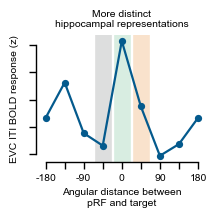

In [4]:
subj = 'sub-22'
stim = 'waterfall_outdoor11'

plot_data = hipp_df_plot.query(
    "cue_validity=='valid' & subj==@subj & next_targ_comp_dist==45 & rank_bin==1 & stim_name==@stim"
).groupby(['subj', 'ang_dist_bin', 'cond', 'stim_name', 'rank_bin'])[['bold', 'bold_z']].mean().reset_index()

f, ax = plt.subplots(1, 1, figsize=(2.2, 2.2))
sns.pointplot(x='ang_dist_bin', y='bold_z',  hue='stim_name', palette=['#045a8d'],
              estimator=np.mean, errorbar='se',linewidth=1.6, ax=ax,
              order = [-180.0, -135.0, -90.0, -45.0, 0.0, 45.0, 90.0, 135.0, 180.0],
              data=plot_data)
ax.set(ylabel='EVC ITI BOLD response (z)', xlabel='Angular distance between\npRF and target',
       title='More distinct\nhippocampal representations')

ax.set(xticks=range(9), xticklabels=["-180", "", "-90", "", "0", "", "90", "", "180"], yticklabels=[])

ax.axvline(x=4, c="#3fa76cb3", ls="-", lw=12, alpha=.2, zorder=-100)
ax.axvline(x=5, c="#e37103b3", ls="-", lw=12, alpha=.2, zorder=-100)
ax.axvline(x=3, c="#909393fe", ls="-", lw=12, alpha=.3, zorder=-100)

sns.despine(trim=True)

ax.legend_ = None

f.tight_layout()
save_fig(f, op.join(save_dir, 'fig5a_moreex'))


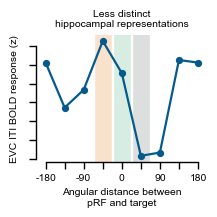

In [5]:
subj = 'sub-14'
stim = 'waterfall_outdoor11'

plot_data = hipp_df_plot.query(
    "cue_validity=='valid' & subj==@subj & next_targ_comp_dist==45 & rank_bin==2 & stim_name==@stim"
).groupby(['subj', 'ang_dist_bin', 'cond', 'stim_name', 'rank_bin'])[['bold', 'bold_z']].mean().reset_index()

f, ax = plt.subplots(1, 1, figsize=(2.2, 2.2))
sns.pointplot(x='ang_dist_bin', y='bold_z',  hue='stim_name', palette=['#045a8d'],
              estimator=np.mean, errorbar='se',linewidth=1.6, ax=ax,
              order = [-180.0, -135.0, -90.0, -45.0, 0.0, 45.0, 90.0, 135.0, 180.0],
              data=plot_data)
ax.set(ylabel='EVC ITI BOLD response (z)', xlabel='Angular distance between\npRF and target',
       title='Less distinct\nhippocampal representations')

ax.set(xticks=range(9), xticklabels=["-180", "", "-90", "", "0", "", "90", "", "180"], yticklabels=[])

ax.axvline(x=4, c="#3fa76cb3", ls="-", lw=12, alpha=.2, zorder=-100)
ax.axvline(x=3, c="#e37103b3", ls="-", lw=12, alpha=.2, zorder=-100)
ax.axvline(x=5, c="#909393fe", ls="-", lw=12, alpha=.3, zorder=-100)

sns.despine(trim=True)

ax.legend_ = None

f.tight_layout()
save_fig(f, op.join(save_dir, 'fig5a_lessex'))


## Fig 5B: EVC responses by pRF distance bin, separated by hippocampal pattern similarity

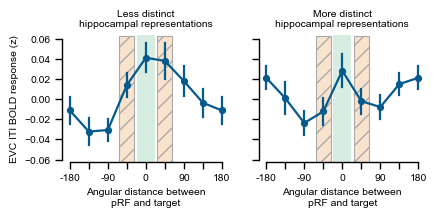

In [6]:
less_distinct_data = hipp_df_plot.query(
    "cue_validity=='valid' & next_targ_comp_dist==45 & rank_bin==2"
).groupby(['subj', 'ang_dist_bin', 'rank_bin'])[['bold', 'bold_z']].mean().reset_index()

more_distinct_data = hipp_df_plot.query(
    "cue_validity=='valid' & next_targ_comp_dist==45 & rank_bin==1"
).groupby(['subj', 'ang_dist_bin', 'rank_bin'])[['bold', 'bold_z']].mean().reset_index()

f, (ax1, ax2) = plt.subplots(1, 2, figsize=(4.4, 2.2))
sns.pointplot(x='ang_dist_bin', y='bold_z',  ax=ax1,
              estimator=np.mean, errorbar='se',linewidth=1.6,
              color = '#045a8d',
              order = [-180.0, -135.0, -90.0, -45.0, 0.0, 45.0, 90.0, 135.0, 180.0],
              data=less_distinct_data)

sns.pointplot(x='ang_dist_bin', y='bold_z', ax=ax2,
              estimator=np.mean, errorbar='se',linewidth=1.6,
              color='#045a8d',
              order = [-180.0, -135.0, -90.0, -45.0, 0.0, 45.0, 90.0, 135.0, 180.0],
              data=more_distinct_data)


ax1.set(ylabel='EVC ITI BOLD response (z)', xlabel='Angular distance between\npRF and target',
        title='Less distinct\nhippocampal representations')
ax2.set(ylabel='', xlabel='Angular distance between\npRF and target',
        title='More distinct\nhippocampal representations')

ax1.set(yticks=np.arange(-.06, .061, .02), ylim=[-.062, .064], xticks=range(9),
        xticklabels=["-180", "", "-90", "", "0", "", "90", "", "180"])
ax2.set(yticks=np.arange(-.06, .061, .02), ylim=[-.062, .064], yticklabels=[], xticks=range(9),
        xticklabels=["-180", "", "-90", "", "0", "", "90", "", "180"])

ax1.axvline(x=4, c="#3fa76cb3", ls="-", lw=13, alpha=.2, zorder=-100)
ax2.axvline(x=4, c="#3fa76cb3", ls="-", lw=13, alpha=.2, zorder=-100)


ax1.bar(3, .125, bottom=-.062, color="#f9e3cdff", alpha=1, edgecolor='#aaaaaa', hatch='//', zorder=-100)
ax2.bar(3, .125, bottom=-.062, color="#f9e3cdff", alpha=1, edgecolor='#aaaaaa', hatch='//', zorder=-100)
ax1.bar(5, .125, bottom=-.062, color="#f9e3cdff", alpha=1, edgecolor='#aaaaaa', hatch='//', zorder=-100)
ax2.bar(5, .125, bottom=-.062, color="#f9e3cdff", alpha=1, edgecolor='#aaaaaa', hatch='//', zorder=-100)

sns.despine(trim=True)

ax1.legend_ = None
ax2.legend_ = None

f.tight_layout(w_pad=2)
save_fig(f, op.join(save_dir, 'fig5b'))

## Fig 5C: Mean EVC response per pRF location, separated by hippocampal pattern similarity

In [7]:
hipp_mean = hipp_df.query(
    "cue_validity=='valid' & next_targ_comp_dist==45"
).groupby(['subj', 'rank_bin', 'cond'])[['bold', 'bold_z']].mean().reset_index()

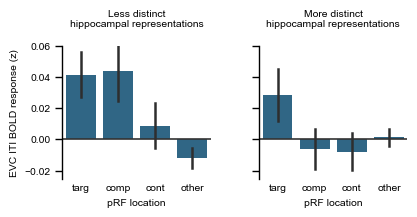

In [8]:
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(4.2, 2.2))

sns.barplot(x='cond', y='bold_z', errorbar='se', color='#045a8d', saturation=.7, alpha=.9,
            err_kws={'color': '.18'}, order=['target', 'competitor', 'control', 'other'],
            data=hipp_mean.query("rank_bin==2"), ax=ax1)
sns.barplot(x='cond', y='bold_z', errorbar='se', color='#045a8d', saturation=.7, alpha=.9,
            err_kws={'color': '.18'}, order=['target', 'competitor', 'control', 'other'],
            data=hipp_mean.query("rank_bin==1"), ax=ax2)

ax1.set(ylabel='EVC ITI BOLD response (z)', xlabel='pRF location',ylim=[-.025, .06],
       xticks=range(4), xticklabels=['targ', 'comp', 'cont', 'other'])
ax2.set(ylabel='', yticklabels=[], xlabel='pRF location',ylim=[-.025, .06],
       xticks=range(4), xticklabels=['targ', 'comp', 'cont', 'other'])
ax1.set_title('Less distinct\nhippocampal representations\n');
ax2.set_title('More distinct\nhippocampal representations\n');
ax1.axhline(y=0, c=".2", ls="-", zorder=1)
ax2.axhline(y=0, c=".2", ls="-", zorder=1)

sns.despine(bottom=True)
ax1.tick_params(axis='x', which='both', size=0)
ax2.tick_params(axis='x', which='both', size=0)

plt.gcf().tight_layout(w_pad=4)
save_fig(plt.gcf(), op.join(save_dir, 'fig5c'))


## Robustness check: excluding fixation-break trials


In [9]:
fix_breaks = pd.read_csv('../dataframes/fix_break_trials.csv')
fix_breaks['subj'] = fix_breaks['subject']

In [10]:
no_fixbreak_df = hipp_df.merge(fix_breaks, on=['subj', 'run', 'trial'],
                                    how='left', indicator=True)
no_fixbreak_df = no_fixbreak_df[no_fixbreak_df['_merge'] == 'left_only'].drop(columns=['_merge'])

In [11]:
no_fixbreak_df.to_csv('../dataframes/hipp_rank_corr_nofixbreaks.csv')